In [1]:
print('hello')

hello


tensors are self updatable in learning phases
tensors = numbers + learning ability == for better output
gpu --- more calculations at one time,very fast
deep learning -- more data signals , complex maths -- large data computations so gpu

# tensors and setup
python donnow what is torch, we need to install it


In [ ]:
!pip3 install torch

In [ ]:
import torch
print(torch.__version__)
# tensor -- small box of numbers
x = torch.tensor([1,2,3,4,5])
print(x)

1d -- 1 2 3
2d -- 1 2 
      3 4

In [ ]:
y = torch.tensor([[1,2],[3,4]])
print(y)

In [ ]:
zeros = torch.zeros(2,3)
ones = torch.ones(2,3)

In [ ]:
r = torch.rand(2,3)

In [ ]:
a = torch.tensor

In [ ]:
i = torch.tensor([[10,20,30],[40,50,60]])
#indexing is bit different in pytorch, we use square brackets to index the tensor
print(i[0,0])
print(i[0,3])

In [ ]:
a = torch.tensor([1,2,3])
b = torch.tensor([4,5,6])
c = a+b
d = a*b

# works number by number, not matrix multiplication,element wise multiplication

In [ ]:
#scalar multiplication - multiply by single number
a = a*2
a = a+2
# it works number by number, not matrix multiplication,element wise multiplication

In [ ]:
# tensor and numpy share the same memory location, so if you change one, the other changes as well
import numpy as np
arr = np.array([1,2,3])
n = torch.from_numpy(arr)
print(n.type())
# arr and n point same memory location, so if you change one, the other changes as well


In [ ]:
import torch

#step 1 - input data x
x = torch.tensor([1.,2.,3.])

#step 2 -- y -- output data
y = torch.tensor([2.,4.6.,8.])

#step 3 -- wrong guesses for w and b
w = torch.tensor(0.0)
b = torch.tensor(0.0)

#step 4 -- predictions
y_pred = w*x + b

loss = ((y_pred-y)**2).mean()


# phase 2 - autograd and training , self fixing or self error reducing mechanism

repeat(s1(guess) - s2(measure) - s3(auto fix) - s4(apply))

In [ ]:
import torch

#requires_grad = True -- tells pytorch to keep track of all the operations on this tensor, so that it can compute gradients later
w = torch.tensor(2.0, requires_grad=True)
x = torch.tensor(4.0)
y = w*x
print(y)
#y will comtain a output and grad_fn = MulBackward -- if result is wrong , torch tell me because of which number the result is wrong, so that it can compute gradients later

# Computation graph

in which step the problem is present to track this we need to graph every thing , record things so that we can backtrack and check where the problem lies -- it's like a hidden path, we dont have to draw graph, we need to write some simple maths application
pytorch's hidden map of how numbers are calculated.

In [ ]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
y_pred = w*x
y_true = torch.tensor(10.0)
print(y_pred)
loss = (y_pred-y_true) ** 2
# y_pred is a hidden map (only when requires_grad is present while creating tensor)
print(loss)
loss.backward()
print(w.grad)
# remember w is trainable parameter, so it has gradient, but x is not trainable parameter, so it does not have gradient
# w.grad > 0 -> w is too small, so we need to increase it
print('Prediction',y_pred.item())
print('True value',y_true.item())
print('Loss',loss.item())
print('Gradient',w.grad.item())
#grad just tells us how much we need to change w to reduce the loss, so we can use it to update w

In [ ]:
#gradient descent -- update w using gradient - manually update
# new_w = w - learning_rate * w.grad

#input data x
x = torch.tensor(2.0)
#learnable parameter w
w = torch.tensor(3.0,requires_grad = True)
#correct answer y_true
y_true = torch.tensor(10.0)
#learning rate
lr = 0.1

y_pred = w*x
loss = (y_pred-y_true)**2
loss.backward()
print('before update',w.item())
print('loss',loss.item())
print('gradient',w.grad.item())

with torch.no_grad(): #do not track the operations inside this block, because we do not want to compute gradients for these operations
    w = w - lr * w.grad
    #after updating w, we need to set the gradient to zero, so that it does not accumulate
w.grad.zero_() #zero_() is an inplace operation, it will change the value of w.grad to zero, but it will not create a new tensor
print('after update',w.item())

In [ ]:
w = torch.tensor(3.0,requires_grad = True)
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)
loss1 = (w*x-y_true)**2
loss1.backward()
print('Gradient of w:', w.grad.item())

loss2 = (w*x-y_true)**2
loss2.backward() 
print('after second backward',w.grad.item())

# training loop -- core loop of a ai system

1 make a prediction -> measure loss -> fina -> gradient descent -> reducing loss

In [ ]:
x = torch.tensor([1.,2.,3.])
y_true = torch.tensor([2.,4.,6.,8.]) #true numbers

w = torch.tensor(0.0,requires_grad = True)

lr = 0.1
epochs = 10

for epoch in range(epochs):
    # prediction
    y_pred = w*x
    # loss
    loss = ((y_pred-y_true)**2).mean()
    # backward pass
    loss.backward()
    # update w
    with torch.no_grad():
        w = w - lr * w.grad
    w.grad.zero_()

# neural network structure and components


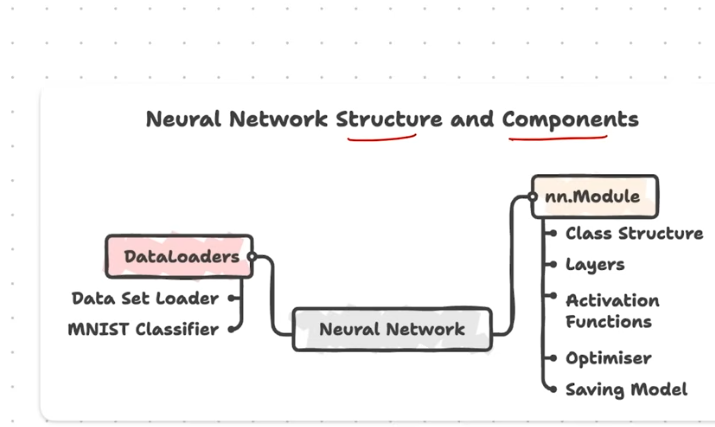

the phase where pytorch really work on deep learning 
till now we just learned about one formula for w 
many steps, many numbers , clean structrues

In [ ]:
w = torch.tensor(0.0,requires_grad = True) # problem is it doesnt work for may layers , for that many weights and biases ,papameters
